# Modelling Human Activity States with a Hidden Markov Model

**Author:** Jolly Gift Burabyo &nbsp;|&nbsp; **Device:** iPhone 11 Pro (iOS), Sensor Logger v1.68 @ 100 Hz

This notebook implements a Gaussian-emission Hidden Markov Model **from scratch in NumPy** to infer four hidden
activity states (*still, standing, walking, jumping*) from smartphone accelerometer + gyroscope signals.

| Section | Content |
|---|---|
| 1 | Data loading, sampling-rate harmonisation, raw-signal visualisation |
| 2 | Windowing and time/frequency feature extraction, Z-score normalisation |
| 3 | HMM components (Z, X, A, B, π) |
| 4 | Implementation: scaled Forward–Backward, Baum–Welch (EM) with log-likelihood convergence, Viterbi |
| 5 | Training, transition & emission visualisations |
| 6 | Evaluation on unseen recordings: decoded sequences, confusion matrix, sensitivity/specificity/accuracy |

In [1]:
import glob, os, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

DATA, FIG = "data", "figures"
os.makedirs(FIG, exist_ok=True)
STATES = ["still", "standing", "walking", "jumping"]
K = len(STATES)
COLORS = dict(zip(STATES, ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]))
FS = 100.0           # harmonised sampling rate (Hz)

## 1. Data collection and pre-processing

* **Recording:** one participant, iPhone 11 Pro, *Sensor Logger* with **Accelerometer, Gravity and Gyroscope** enabled
  at the app's 100 Hz setting. The phone was held at waist level (screen facing the user) for *standing / walking /
  jumping* and placed flat on a table for *still*.
* **Training set:** 13 clips × 4 activities = **52 files** of ~10 s each, recorded in the bedroom.
* **Unseen test set:** 2 continuous ~40 s recordings containing several activities in sequence, recorded later in a
  **different room (living room)**; ground-truth segment times are in `data/raw/test/segments.csv`.

**Pre-processing (`prepare_data.py`)**
1. Sensor Logger's *Accelerometer* stream is *linear* acceleration (gravity removed). We add the *Gravity* stream back
   to recover the true raw accelerometer signal, so that phone orientation (flat vs upright) is preserved.
2. **Sampling-rate harmonisation:** iOS Core Motion does not deliver samples on a perfectly regular clock; the measured
   rate is ≈ 99.3 Hz with jittering intervals. All streams are aligned on `seconds_elapsed` and **linearly interpolated
   onto an exact 100 Hz grid**, so every file has identical Δt = 10 ms. This also makes the pipeline phone-agnostic:
   recordings from a device logging at e.g. 50 Hz or 200 Hz would be resampled to the same grid before windowing.
3. The first and last **1 s** of every training clip is trimmed to remove the button-press artefacts.

In [2]:
meta = pd.read_csv(f"{DATA}/metadata.csv")
summary = (meta.groupby(["split", "activity"])
               .agg(files=("file", "count"), total_seconds=("clean_duration_s", "sum"),
                    mean_measured_hz=("measured_hz", "mean"), min_hz=("measured_hz", "min"),
                    max_hz=("measured_hz", "max"))
               .round(2))
summary

files  total_seconds  mean_measured_hz  min_hz  max_hz
split activity                                                        
test  mixed         2          85.63             99.30   99.30   99.31
train jumping      13         117.08             99.29   99.29   99.30
      standing     13         109.81             99.28   99.28   99.29
      still        13         111.46             99.28   99.26   99.29
      walking      13         114.06             99.29   99.28   99.29

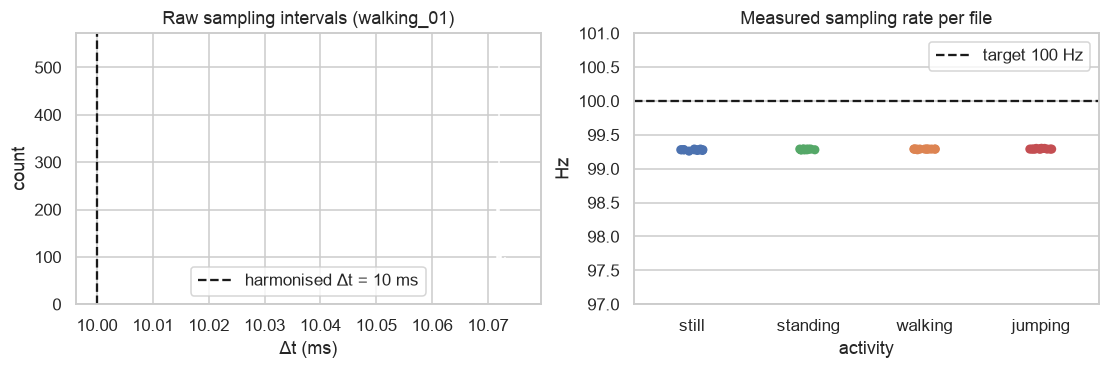

raw Δt: mean 10.07 ms, std 0.00 ms -> effective 99.3 Hz


In [3]:
# Raw timing jitter (before resampling) vs the harmonised grid
with zipfile.ZipFile(f"{DATA}/raw/walking/walking_01.zip") as zf:
    raw = pd.read_csv(io.BytesIO(zf.read("Accelerometer.csv")))
dt_ms = np.diff(raw["seconds_elapsed"].values) * 1000

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].hist(dt_ms, bins=60, color="#4C72B0")
ax[0].axvline(10, color="k", ls="--", label="harmonised Δt = 10 ms")
ax[0].set(title="Raw sampling intervals (walking_01)", xlabel="Δt (ms)", ylabel="count"); ax[0].legend()
meta_tr = meta[meta.split == "train"]
sns.stripplot(data=meta_tr, x="activity", y="measured_hz", order=STATES, hue="activity", palette=COLORS, legend=False, ax=ax[1], size=6)
ax[1].axhline(100, color="k", ls="--", label="target 100 Hz")
ax[1].set(title="Measured sampling rate per file", ylabel="Hz", ylim=(97, 101)); ax[1].legend()
plt.savefig(f"{FIG}/fig1_sampling_rate.png"); plt.show()
print(f"raw Δt: mean {dt_ms.mean():.2f} ms, std {dt_ms.std():.2f} ms -> effective {1000/dt_ms.mean():.1f} Hz")

In [4]:
def load_split(pattern):
    out = []
    for p in sorted(glob.glob(pattern)):
        out.append({"file": os.path.basename(p)[:-4], "df": pd.read_csv(p)})
    return out

train = {s: load_split(f"{DATA}/train/{s}/*.csv") for s in STATES}
test = load_split(f"{DATA}/test/test_*.csv")
print({s: len(v) for s, v in train.items()}, "| test files:", [t["file"] for t in test])

{'still': 13, 'standing': 13, 'walking': 13, 'jumping': 13} | test files: ['test_01', 'test_02']


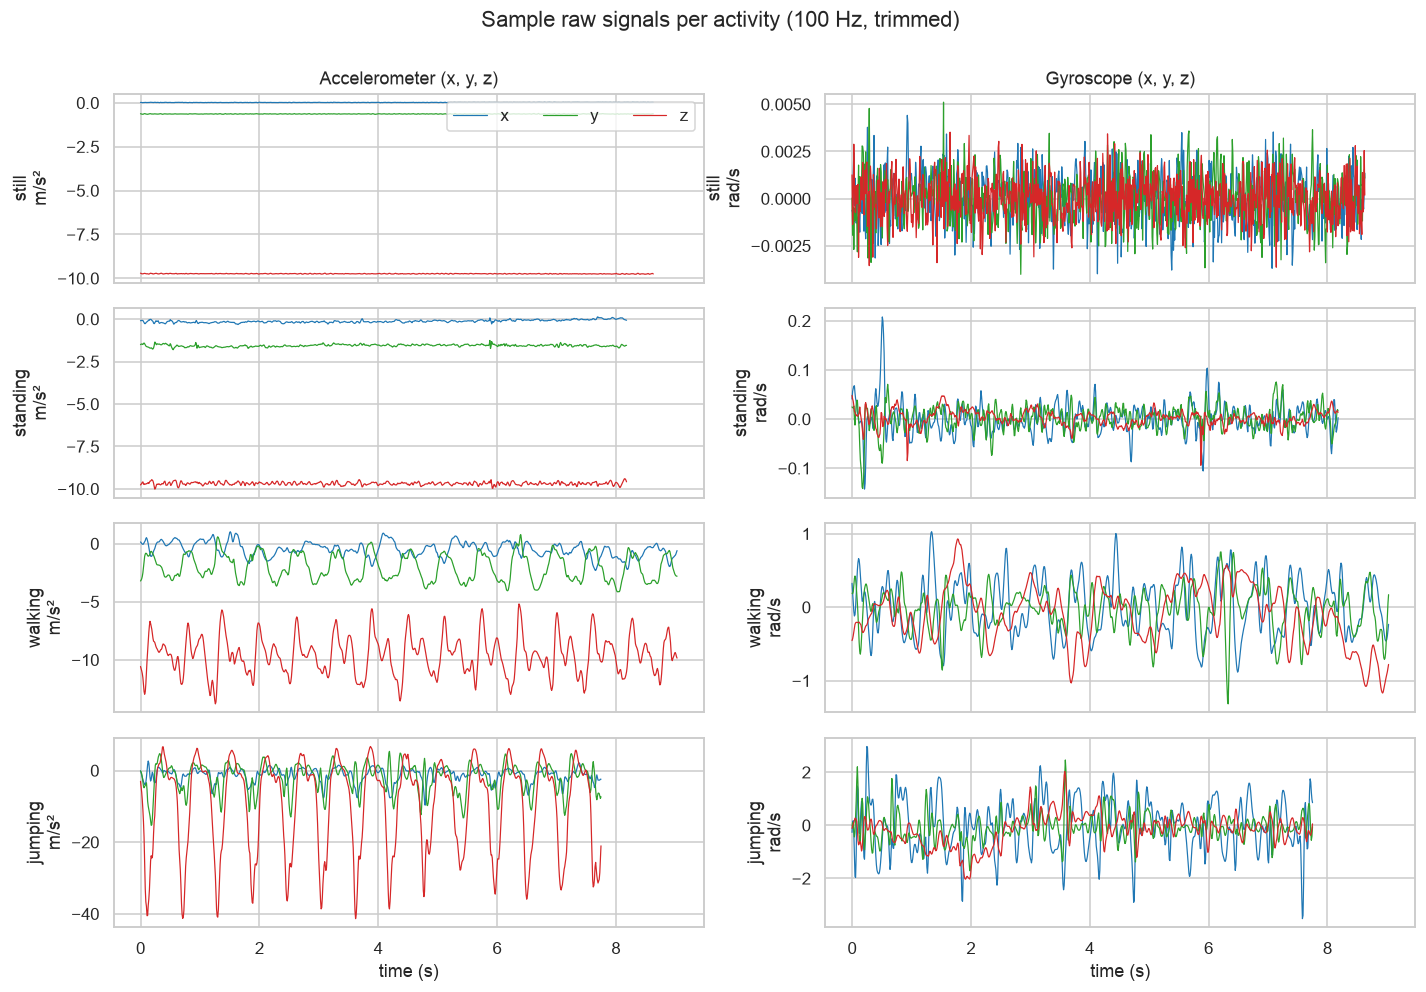

In [5]:
# Visualise one clip per activity: raw accelerometer and gyroscope
fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
for i, s in enumerate(STATES):
    df = train[s][0]["df"]
    for j, (sensor, unit) in enumerate([("acc", "m/s²"), ("gyro", "rad/s")]):
        for ax_name, c in zip("xyz", ["#1f77b4", "#2ca02c", "#d62728"]):
            axes[i, j].plot(df.seconds_elapsed, df[f"{sensor}_{ax_name}"], lw=0.8, c=c, label=ax_name)
        axes[i, j].set_ylabel(f"{s}\n{unit}")
axes[0, 0].set_title("Accelerometer (x, y, z)"); axes[0, 1].set_title("Gyroscope (x, y, z)")
axes[0, 0].legend(loc="upper right", ncol=3); axes[-1, 0].set_xlabel("time (s)"); axes[-1, 1].set_xlabel("time (s)")
plt.suptitle("Sample raw signals per activity (100 Hz, trimmed)", y=1.0)
plt.tight_layout(); plt.savefig(f"{FIG}/fig2_raw_signals.png"); plt.show()

## 2. Windowing and feature extraction

**Window size.** At the harmonised 100 Hz rate we use **2 s windows (N = 200 samples) with 50 % overlap (hop = 100
samples = 1 s)**:
* Walking cadence (~1.8–2 steps/s) and jumping rate (~2 jumps/s) mean each window contains **≈4 complete motion
  cycles**, enough for stable statistics and a clear spectral peak.
* FFT bin width is fs/N = 100/200 = **0.5 Hz**; we zero-pad to 1024 points (0.1 Hz interpolation) for the dominant
  frequency estimate. The Nyquist limit (50 Hz) is far above human motion content (< 20 Hz).
* A 1 s hop gives one HMM observation per second: short enough to localise transitions, long enough that each
  observation is informative. Each ~8 s cleaned clip yields ~7 windows.

**Features (8 per window).** Let *a* = ‖acc‖ and *ω* = ‖gyro‖ (magnitudes are orientation-invariant).

| # | Feature | Domain | Why it separates the activities |
|---|---|---|---|
| 1 | `acc_std` – std of *a* | time | Motion intensity: ≈0 still → small standing tremor → walking → very large jumping impacts |
| 2 | `acc_sma` – signal magnitude area of mean-removed acc axes | time | Total dynamic acceleration over all 3 axes; robust intensity measure |
| 3 | `gyro_mean` – mean *ω* | time | Rotation: phone on table has *zero* rotation, hand-held standing has small tremor rotation (key still↔standing cue) |
| 4 | `tilt` – mean(acc_z)/mean(*a*) | time | Cosine of phone tilt w.r.t. gravity; captures how the phone is held/placed |
| 5 | `corr_yz` – Pearson correlation acc_y vs acc_z | time | Axis coupling: vertical bouncing in jumping/walking moves y and z together; near 0 for noise-only signals |
| 6 | `dom_freq` – frequency of max FFT magnitude of *a* (0.5–20 Hz) | frequency | Step/jump rhythm (~2 Hz) vs. no periodicity for still/standing |
| 7 | `spec_energy` – Σ\|FFT\|²/N in 0.5–20 Hz | frequency | Energy of periodic motion; orders of magnitude apart between classes |
| 8 | `spec_entropy` – normalised Shannon entropy of the power spectrum | frequency | Peaked spectrum (rhythmic walking/jumping) → low; flat noise spectrum (still) → high |

**Normalisation.** Intensity features (1, 2, 3, 7) span several orders of magnitude and are strongly right-skewed, so we
take `log10` first, making them approximately Gaussian (matching our Gaussian emission model). Then all features are
**Z-score standardised** (*x' = (x − μ)/σ*) using μ, σ computed on the **training set only** and re-used on test data
(no leakage). Z-scoring puts all features on a common scale so no single feature dominates the emission likelihood and
the variance floor in Baum–Welch has the same meaning for every dimension.

In [6]:
WIN, HOP = int(2 * FS), int(1 * FS)
NFFT = 1024
FEATURES = ["acc_std", "acc_sma", "gyro_mean", "tilt", "corr_yz", "dom_freq", "spec_energy", "spec_entropy"]
LOG_FEATURES = ["acc_std", "acc_sma", "gyro_mean", "spec_energy"]
EPS = 1e-6


def window_features(w):
    # Compute the 8 features for one window (DataFrame slice of WIN samples).
    acc = w[["acc_x", "acc_y", "acc_z"]].to_numpy()
    gyr = w[["gyro_x", "gyro_y", "gyro_z"]].to_numpy()
    a = np.linalg.norm(acc, axis=1)
    om = np.linalg.norm(gyr, axis=1)
    dyn = acc - acc.mean(axis=0)

    f = {}
    f["acc_std"] = a.std()
    f["acc_sma"] = np.abs(dyn).sum(axis=1).mean()
    f["gyro_mean"] = om.mean()
    f["tilt"] = acc[:, 2].mean() / a.mean()
    cy, cz = dyn[:, 1], dyn[:, 2]
    den = cy.std() * cz.std()
    f["corr_yz"] = float(np.mean(cy * cz) / den) if den > 1e-9 else 0.0

    # frequency domain: Hann-windowed, zero-padded FFT of the mean-removed magnitude
    x = (a - a.mean()) * np.hanning(len(a))
    spec = np.abs(np.fft.rfft(x, n=NFFT)) ** 2
    freqs = np.fft.rfftfreq(NFFT, d=1 / FS)
    band = (freqs >= 0.5) & (freqs <= 20)
    p = spec[band]
    f["dom_freq"] = freqs[band][np.argmax(p)]
    f["spec_energy"] = p.sum() / len(a)
    pn = p / (p.sum() + EPS)
    f["spec_entropy"] = -(pn * np.log(pn + EPS)).sum() / np.log(len(pn))
    return f


def extract(df):
    # Slide a WIN/HOP window over a recording -> (features DataFrame, majority label, centre time).
    rows = []
    for start in range(0, len(df) - WIN + 1, HOP):
        w = df.iloc[start:start + WIN]
        f = window_features(w)
        f["label"] = w["label"].mode().iloc[0]
        f["t_center"] = w["seconds_elapsed"].iloc[WIN // 2]
        rows.append(f)
    out = pd.DataFrame(rows)
    for c in LOG_FEATURES:
        out[c] = np.log10(out[c] + EPS)
    return out


train_feats = []   # one feature DataFrame per clip
for s in STATES:
    for clip in train[s]:
        fdf = extract(clip["df"]); fdf["clip"] = clip["file"]; train_feats.append(fdf)
test_feats = [extract(t["df"]).assign(clip=t["file"]) for t in test]

all_train = pd.concat(train_feats, ignore_index=True)
print("training windows per activity:", all_train.label.value_counts().reindex(STATES).to_dict())

training windows per activity: {'still': 91, 'standing': 91, 'walking': 94, 'jumping': 97}


In [7]:
# Z-score normalisation fitted on TRAINING windows only
MU = all_train[FEATURES].mean()
SD = all_train[FEATURES].std()
zscore = lambda fdf: ((fdf[FEATURES] - MU) / SD).to_numpy()

pd.DataFrame({"train mean": MU, "train std": SD}).round(3)

,train mean,train std
acc_std,-0.428,1.153
acc_sma,-0.224,1.100
gyro_mean,-0.981,1.194
tilt,-0.940,0.080
corr_yz,0.102,0.320
dom_freq,5.771,4.124
spec_energy,1.400,2.333
spec_entropy,0.746,0.117


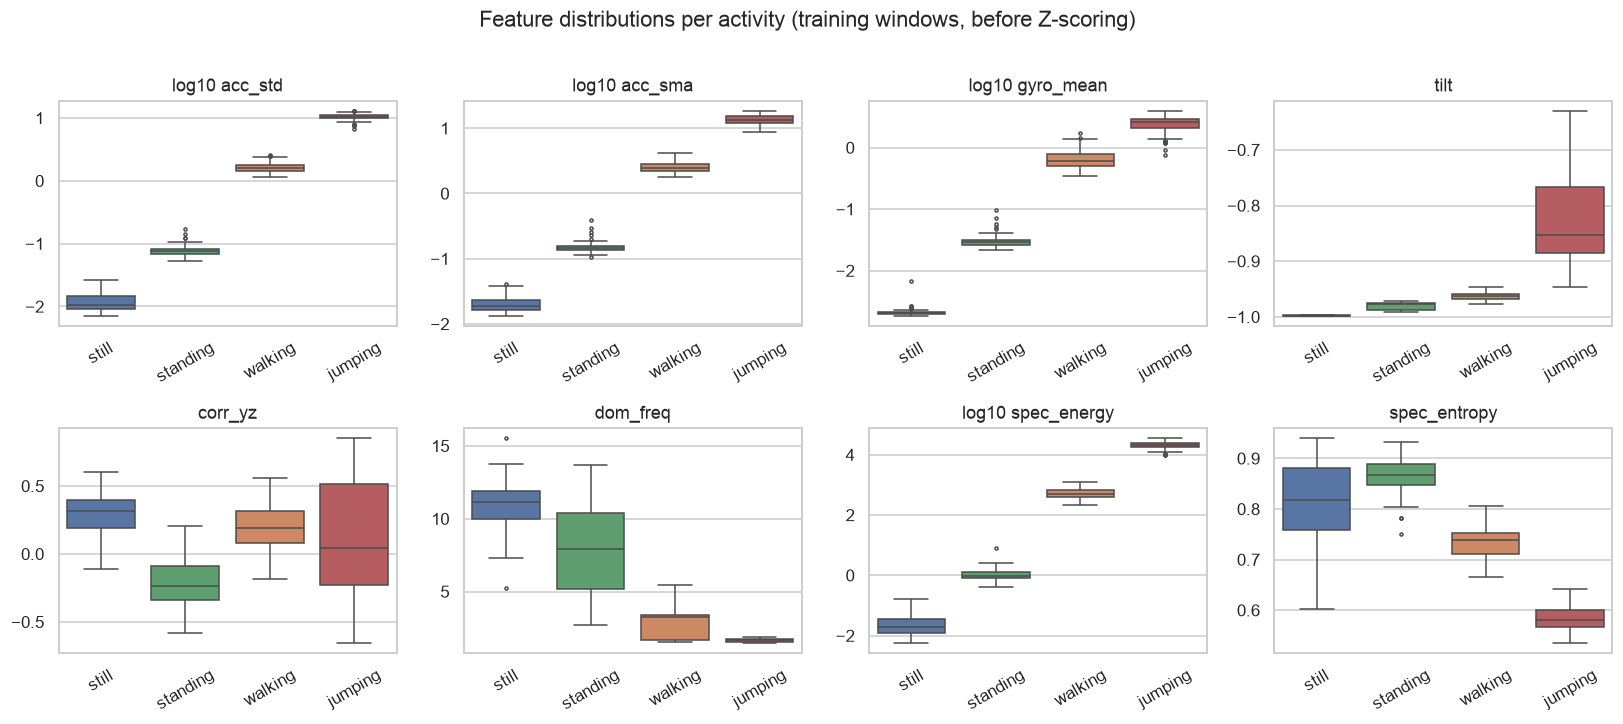

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
labels_disp = {"acc_std": "log10 acc_std", "acc_sma": "log10 acc_sma", "gyro_mean": "log10 gyro_mean",
               "spec_energy": "log10 spec_energy"}
for ax, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=all_train, x="label", y=f, order=STATES, hue="label", palette=COLORS, legend=False, ax=ax, fliersize=2)
    ax.set(title=labels_disp.get(f, f), xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Feature distributions per activity (training windows, before Z-scoring)", y=1.01)
plt.tight_layout(); plt.savefig(f"{FIG}/fig3_features.png"); plt.show()

## 3. HMM components

| Element | Definition in this project |
|---|---|
| **Hidden states Z** | *z_t* ∈ {still, standing, walking, jumping}, K = 4, the activity during 1-s step *t* |
| **Observations X** | *x_t* ∈ ℝ⁸, the Z-scored feature vector of the 2-s window centred at *t* |
| **Transition matrix A** | *A_ij = P(z_{t+1}=j \| z_t=i)*, 4×4, rows sum to 1 |
| **Emission model B** | *P(x_t \| z_t=k) = 𝒩(x_t; μ_k, diag σ²_k)*, a diagonal-covariance Gaussian per state (continuous observations, so B is a density rather than a table) |
| **Initial distribution π** | *π_k = P(z_1 = k)* |

**Training sequences.** Each training clip contains only one activity, so on its own it carries no information about
*between*-activity transitions. To learn A we chain the clip feature-sequences into **pseudo-continuous sessions** that
follow a plausible daily routine: phone on table → pick it up and stand → walk → exercise (jump) → walk → stand → put
the phone down (still → standing → walking → jumping → walking → standing → …). Windows are computed **inside** each clip
before chaining, so no window straddles two clips. Clips not used in a session are added as additional single-activity
sequences. A small Dirichlet pseudo-count (0.1) on transition counts keeps every transition possible (never exactly 0).

## 4. Algorithm choice and implementation

* **Baum–Welch (EM)** is used for *learning* π, A, μ, σ² because the model has latent states: the E-step (scaled
  Forward–Backward) computes state posteriors γ and expected transition counts ξ, the M-step re-estimates the
  parameters in closed form. It maximises the data log-likelihood, and we stop when the improvement per observation is
  below ε = 10⁻⁴ (`max_iter` is only a safety cap). Means/variances are **initialised from the labelled windows**, which
  anchors each hidden state to its activity (avoids label switching and poor local optima).
* **Viterbi** is used for *decoding*: it returns the single most likely state sequence argmax P(z₁:T | x₁:T), which is
  exactly what our evaluation metrics (sensitivity, specificity, accuracy computed from a per-window predicted label)
  require. Using the joint path (rather than per-window posterior argmax) enforces temporally consistent labels,
  suppressing isolated mis-classifications, which directly improves sensitivity/specificity on the unseen sessions.
* The **Forward algorithm** also gives log P(X), used for the convergence check.

All computations use **scaling** (forward–backward) or **log-space** (Viterbi, emissions) to avoid numerical underflow.

In [9]:
class GaussianHMM:
    # Hidden Markov Model with diagonal-covariance Gaussian emissions (NumPy only).
    #
    # Parameters
    #   pi    : (K,)   initial state distribution
    #   A     : (K,K)  transition matrix, A[i, j] = P(z_{t+1}=j | z_t=i)
    #   means : (K,D)  emission means
    #   vars  : (K,D)  emission variances (diagonal covariance)

    def __init__(self, n_states, var_floor=1e-2, trans_pseudocount=0.1, learn_pi=True, state_names=None):
        self.K = n_states
        self.var_floor = var_floor
        self.trans_pseudocount = trans_pseudocount
        self.learn_pi = learn_pi
        self.state_names = state_names or list(range(n_states))

    # ---------- emissions ----------
    def log_emissions(self, X):
        # log N(x_t | mu_k, diag(var_k)) for every t, k  -> (T, K)
        diff = X[:, None, :] - self.means[None, :, :]
        return -0.5 * (np.log(2 * np.pi * self.vars).sum(axis=1)[None, :]
                       + (diff ** 2 / self.vars[None, :, :]).sum(axis=2))

    # ---------- E-step: scaled forward-backward ----------
    def forward_backward(self, X):
        # Returns gamma (T,K), expected transition counts xi_sum (K,K), log P(X).
        logB = self.log_emissions(X)
        T = len(X)
        shift = logB.max(axis=1, keepdims=True)          # per-t constant for numerical stability
        B = np.exp(logB - shift)
        alpha, beta, c = np.empty((T, self.K)), np.empty((T, self.K)), np.empty(T)

        alpha[0] = self.pi * B[0]
        c[0] = alpha[0].sum(); alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ self.A) * B[t]
            c[t] = alpha[t].sum(); alpha[t] /= c[t]

        beta[-1] = 1.0
        for t in range(T - 2, -1, -1):
            beta[t] = self.A @ (B[t + 1] * beta[t + 1]) / c[t + 1]

        gamma = alpha * beta
        gamma /= gamma.sum(axis=1, keepdims=True)
        # xi_sum[i,j] = sum_t P(z_t=i, z_{t+1}=j | X)
        xi_sum = self.A * (alpha[:-1].T @ ((B[1:] * beta[1:]) / c[1:, None]))
        loglik = np.log(c).sum() + shift.sum()
        return gamma, xi_sum, loglik

    def score(self, X):
        return self.forward_backward(X)[2]

    def predict_proba(self, X):
        return self.forward_backward(X)[0]

    # ---------- learning: Baum-Welch ----------
    def init_from_labels(self, sequences, labels, self_prob=0.9):
        # Supervised initialisation of mu, var (per-state statistics), uniform pi, sticky A.
        X = np.vstack(sequences); y = np.concatenate(labels)
        self.means = np.array([X[y == k].mean(axis=0) for k in range(self.K)])
        self.vars = np.array([np.maximum(X[y == k].var(axis=0), self.var_floor) for k in range(self.K)])
        self.pi = np.full(self.K, 1 / self.K)
        self.A = np.full((self.K, self.K), (1 - self_prob) / (self.K - 1))
        np.fill_diagonal(self.A, self_prob)
        return self

    def fit(self, sequences, tol=1e-4, max_iter=500, verbose=True):
        # Baum-Welch over multiple sequences. Stops when the log-likelihood gain per
        # observation < tol (convergence criterion); max_iter is only a safety cap.
        n_obs = sum(len(X) for X in sequences)
        self.history, prev = [], -np.inf
        self.converged = False
        for it in range(max_iter):
            pi_acc = np.zeros(self.K); A_acc = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); x_sum = np.zeros_like(self.means); x2_sum = np.zeros_like(self.means)
            ll = 0.0
            for X in sequences:                                   # E-step
                gamma, xi_sum, l = self.forward_backward(X)
                pi_acc += gamma[0]; A_acc += xi_sum; g_sum += gamma.sum(axis=0)
                x_sum += gamma.T @ X; x2_sum += gamma.T @ (X ** 2); ll += l
            self.history.append(ll)

            gain = (ll - prev) / n_obs
            if verbose and (it < 3 or it % 10 == 0):
                print(f"iter {it:3d}  log-likelihood {ll:11.3f}  gain/obs {gain:.2e}")
            if it > 0 and abs(gain) < tol:
                self.converged = True
                if verbose: print(f"converged at iteration {it}: |ΔLL|/N = {abs(gain):.2e} < tol = {tol}")
                break
            prev = ll

            if self.learn_pi:                                     # M-step
                self.pi = (pi_acc + 1e-3) / (pi_acc + 1e-3).sum()
            A_new = A_acc + self.trans_pseudocount
            self.A = A_new / A_new.sum(axis=1, keepdims=True)
            self.means = x_sum / g_sum[:, None]
            self.vars = np.maximum(x2_sum / g_sum[:, None] - self.means ** 2, self.var_floor)
        if not self.converged and verbose:
            print("WARNING: reached max_iter without meeting tolerance")
        return self

    # ---------- decoding: Viterbi ----------
    def viterbi(self, X):
        # Most likely state path (log-space). Returns (path, log P(path, X)).
        logB = self.log_emissions(X)
        logA, T = np.log(self.A), len(X)
        delta = np.log(self.pi) + logB[0]
        psi = np.zeros((T, self.K), dtype=int)
        for t in range(1, T):
            scores = delta[:, None] + logA                       # (from i, to j)
            psi[t] = scores.argmax(axis=0)
            delta = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int); path[-1] = delta.argmax()
        for t in range(T - 1, 0, -1):
            path[t - 1] = psi[t, path[t]]
        return path, delta.max()

    def sample(self, T, rng):
        # Draw a synthetic (states, observations) sequence; used to unit-test the implementation.
        z = np.empty(T, dtype=int); z[0] = rng.choice(self.K, p=self.pi)
        for t in range(1, T):
            z[t] = rng.choice(self.K, p=self.A[z[t - 1]])
        X = self.means[z] + rng.standard_normal((T, self.means.shape[1])) * np.sqrt(self.vars[z])
        return z, X

### 4.1 Sanity check on synthetic data
Before touching the real data, we verify the implementation: sample sequences from a *known* HMM, re-learn it with
Baum–Welch from a perturbed start, and check that (i) the log-likelihood increases monotonically, (ii) A is recovered and
(iii) Viterbi recovers the hidden path.

In [10]:
rng = np.random.default_rng(0)
true = GaussianHMM(3)
true.pi = np.array([0.6, 0.3, 0.1])
true.A = np.array([[0.90, 0.08, 0.02], [0.05, 0.90, 0.05], [0.02, 0.08, 0.90]])
true.means = np.array([[-2.0, 0.0], [0.0, 2.0], [2.0, -1.0]]); true.vars = np.full((3, 2), 0.5)
seqs = [true.sample(200, rng) for _ in range(10)]

est = GaussianHMM(3)
est.init_from_labels([X for _, X in seqs], [z for z, _ in seqs], self_prob=0.5)
est.means += rng.normal(0, 0.5, est.means.shape)              # perturb the start
est.fit([X for _, X in seqs], tol=1e-6, verbose=False)
z0, X0 = seqs[0]
print("monotone log-likelihood:", bool(np.all(np.diff(est.history) > -1e-6)), "| iterations:", len(est.history))
print("max |A_est - A_true| =", np.abs(est.A - true.A).max().round(3))
print("Viterbi path accuracy on synthetic sequence:", (est.viterbi(X0)[0] == z0).mean().round(3))

monotone log-likelihood: True | iterations: 7
max |A_est - A_true| = 0.041
Viterbi path accuracy on synthetic sequence: 0.995


## 5. Training on the recorded data

In [11]:
rng = np.random.default_rng(42)
S_IDX = {s: i for i, s in enumerate(STATES)}
clip_seqs = {s: [(zscore(f), np.full(len(f), S_IDX[s])) for f in train_feats if f.label.iloc[0] == s] for s in STATES}
for s in STATES:
    rng.shuffle(clip_seqs[s])

ROUTINE = ["still", "standing", "walking", "jumping", "walking", "standing"]
pools = {s: list(v) for s, v in clip_seqs.items()}
sessions, current = [], []
need = pd.Series(ROUTINE).value_counts()
while all(len(pools[s]) >= n for s, n in need.items()):   # build cycles while clips remain
    for s in ROUTINE:
        current.append(pools[s].pop())
    if len(current) >= 3 * len(ROUTINE):         # 3 routine cycles per session
        sessions.append(current); current = []
if current: sessions.append(current)
leftovers = [c for s in STATES for c in pools[s]]

train_X = [np.vstack([c[0] for c in sess]) for sess in sessions] + [c[0] for c in leftovers]
train_y = [np.concatenate([c[1] for c in sess]) for sess in sessions] + [c[1] for c in leftovers]
print(f"{len(sessions)} routine sessions ({[len(x) for x in train_X[:len(sessions)]]} windows) "
      f"+ {len(leftovers)} single-activity clips; total windows = {sum(map(len, train_X))}")

2 routine sessions ([128, 128] windows) + 16 single-activity clips; total windows = 373


In [12]:
# π is kept uniform: the start state of our constructed training sequences is an artefact of how we chained clips,
# so learning it would only encode that artefact; a uniform prior makes no assumption about the first activity.
hmm = GaussianHMM(K, learn_pi=False, state_names=STATES).init_from_labels(train_X, train_y, self_prob=0.9)
init_snapshot = {k: getattr(hmm, k).copy() for k in ["pi", "A", "means", "vars"]}
hmm.fit(train_X, tol=1e-4, max_iter=500)

# check that each hidden state is still anchored to its activity after unsupervised EM
moved = np.linalg.norm(hmm.means - init_snapshot["means"], axis=1)
print("distance of learned means from initial (labelled) means:", dict(zip(STATES, moved.round(3))))

iter   0  log-likelihood    1100.055  gain/obs inf
iter   1  log-likelihood    1123.289  gain/obs 6.23e-02
iter   2  log-likelihood    1123.289  gain/obs 0.00e+00
converged at iteration 2: |ΔLL|/N = 0.00e+00 < tol = 0.0001
distance of learned means from initial (labelled) means: {'still': np.float64(0.0), 'standing': np.float64(0.0), 'walking': np.float64(0.0), 'jumping': np.float64(0.0)}


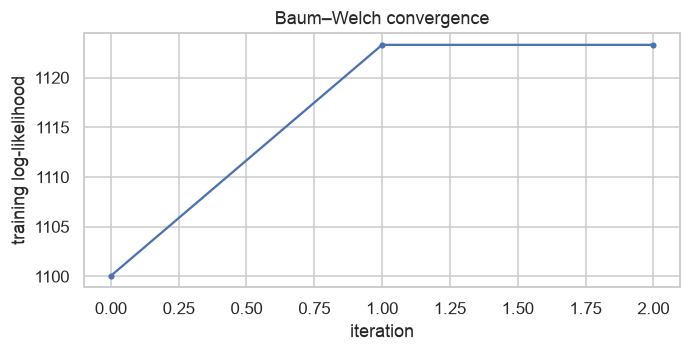

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(hmm.history, marker="o", ms=3)
ax.set(title="Baum–Welch convergence", xlabel="iteration", ylabel="training log-likelihood")
plt.savefig(f"{FIG}/fig4_convergence.png"); plt.show()

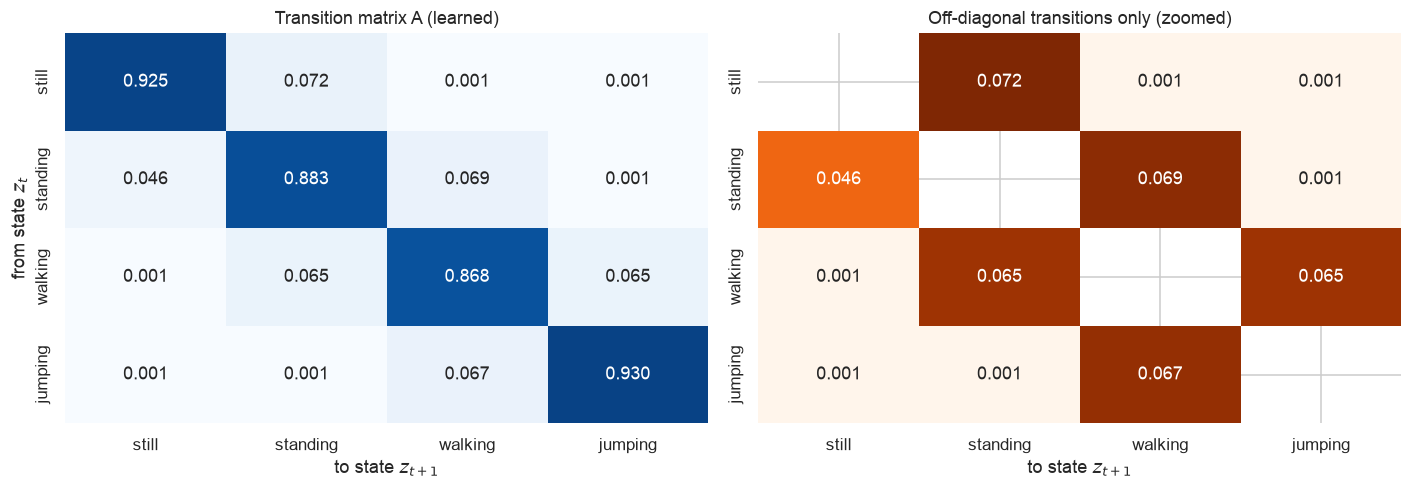

initial distribution π: {'still': np.float64(0.25), 'standing': np.float64(0.25), 'walking': np.float64(0.25), 'jumping': np.float64(0.25)}
expected bout length 1/(1-A_ii) in windows (s): {'still': np.float64(13.4), 'standing': np.float64(8.6), 'walking': np.float64(7.6), 'jumping': np.float64(14.3)}


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(pd.DataFrame(hmm.A, STATES, STATES), annot=True, fmt=".3f", cmap="Blues", ax=ax[0], cbar=False,
            vmin=0, vmax=1)
ax[0].set(title="Transition matrix A (learned)", xlabel="to state $z_{t+1}$", ylabel="from state $z_t$")
sns.heatmap(pd.DataFrame(hmm.A, STATES, STATES).where(~np.eye(K, dtype=bool)), annot=True, fmt=".3f",
            cmap="Oranges", ax=ax[1], cbar=False)
ax[1].set(title="Off-diagonal transitions only (zoomed)", xlabel="to state $z_{t+1}$", ylabel="")
plt.tight_layout(); plt.savefig(f"{FIG}/fig5_transition_matrix.png"); plt.show()
print("initial distribution π:", dict(zip(STATES, hmm.pi.round(3))))
print("expected bout length 1/(1-A_ii) in windows (s):", dict(zip(STATES, (1 / (1 - np.diag(hmm.A))).round(1))))

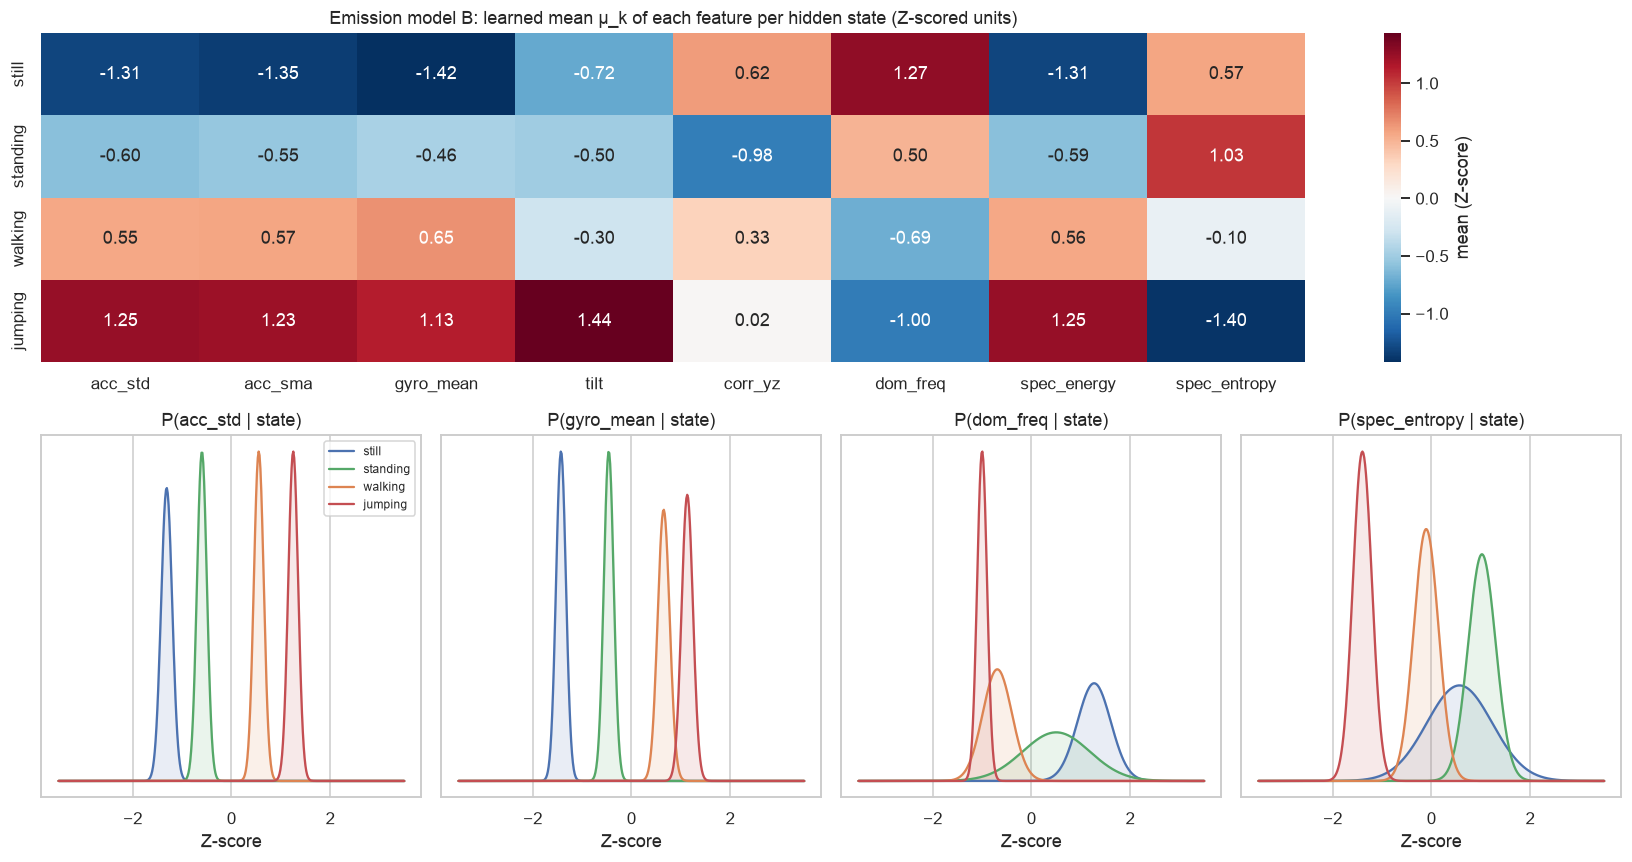

In [15]:
# Emission probabilities: (a) learned state means, (b) Gaussian emission densities for key features
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.1])
ax0 = fig.add_subplot(gs[0, :])
sns.heatmap(pd.DataFrame(hmm.means, STATES, FEATURES), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax0,
            cbar_kws={"label": "mean (Z-score)"})
ax0.set(title="Emission model B: learned mean μ_k of each feature per hidden state (Z-scored units)")
for i, f in enumerate(["acc_std", "gyro_mean", "dom_freq", "spec_entropy"]):
    ax = fig.add_subplot(gs[1, i]); d = FEATURES.index(f)
    xs = np.linspace(-3.5, 3.5, 400)
    for k, s in enumerate(STATES):
        m, v = hmm.means[k, d], hmm.vars[k, d]
        ax.plot(xs, np.exp(-(xs - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v), c=COLORS[s], label=s)
        ax.fill_between(xs, np.exp(-(xs - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v), color=COLORS[s], alpha=0.12)
    ax.set(title=f"P({f} | state)", xlabel="Z-score", yticks=[])
    if i == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/fig6_emissions.png"); plt.show()

## 6. Evaluation on unseen data

The two test recordings were made **after** training data collection, in a **different room** (living room vs bedroom),
as single continuous sessions with natural transitions (including picking the phone up / putting it down). They were never
used for fitting the normalisation statistics or the HMM. Each 1-s window gets the majority ground-truth label; windows
dominated by the unscored *transition* moments (handling the phone) are decoded as part of the sequence but excluded
from the metrics.

For each state *k* (one-vs-rest): **Sensitivity** = TP/(TP+FN), **Specificity** = TN/(TN+FP),
**Accuracy** = (TP+TN)/N; the overall accuracy is the fraction of all scored windows labelled correctly.

In [16]:
def decode(model, fdf):
    path, _ = model.viterbi(zscore(fdf))
    return np.array(STATES)[path], model.predict_proba(zscore(fdf))

for fdf in test_feats:
    fdf["pred"], post = decode(hmm, fdf)
    fdf[[f"p_{s}" for s in STATES]] = post

test_all = pd.concat(test_feats, ignore_index=True)
scored = test_all[test_all.label.isin(STATES)]
print("scored test windows:", len(scored), "| excluded transition windows:", (~test_all.label.isin(STATES)).sum())

scored test windows: 80 | excluded transition windows: 3


In [17]:
def metrics_table(y_true, y_pred):
    rows = []
    N = len(y_true)
    for s in STATES:
        tp = np.sum((y_true == s) & (y_pred == s)); fn = np.sum((y_true == s) & (y_pred != s))
        fp = np.sum((y_true != s) & (y_pred == s)); tn = N - tp - fn - fp
        rows.append({"State (Activity)": s, "Number of Samples": int(tp + fn),
                     "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan,
                     "Accuracy (one-vs-rest)": (tp + tn) / N})
    t = pd.DataFrame(rows)
    t["Overall Accuracy"] = np.mean(y_true == y_pred)
    return t

results = metrics_table(scored.label.values, scored.pred.values)
results.round(3)

,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest),Overall Accuracy
0,still,15,0.867,1.000,0.975,0.862
1,standing,18,0.722,0.984,0.925,0.862
2,walking,29,0.862,0.882,0.875,0.862
3,jumping,18,1.000,0.935,0.950,0.862


accuracy per unseen file: {'test_01': np.float64(0.897), 'test_02': np.float64(0.829)}


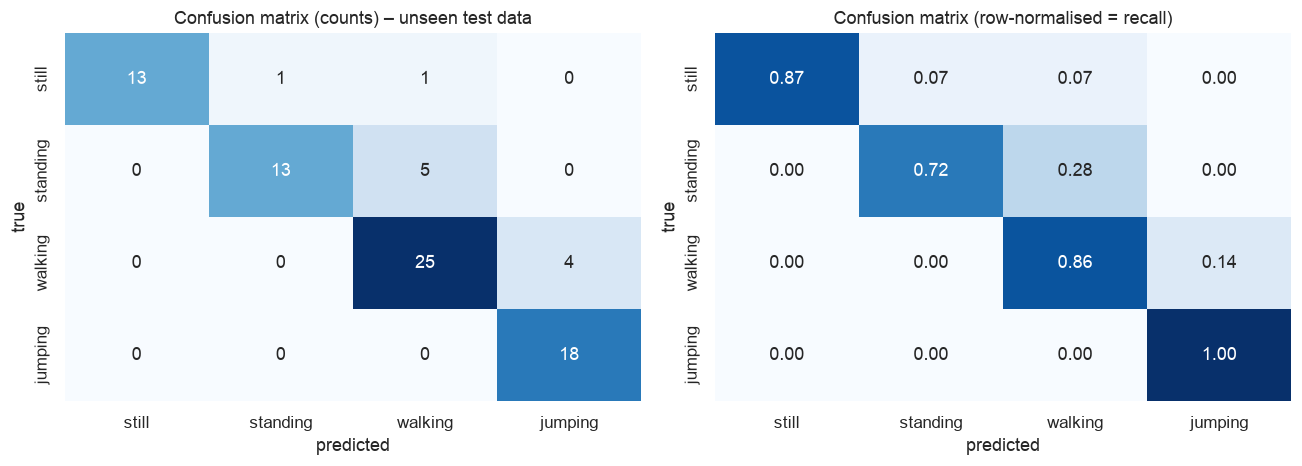

In [18]:
from collections import OrderedDict
per_file = OrderedDict()
for f in test_feats:
    m = f.label.isin(STATES)
    per_file[f["clip"].iloc[0]] = np.mean(f.label[m] == f.pred[m])
print("accuracy per unseen file:", {k: round(v, 3) for k, v in per_file.items()})

cm = pd.crosstab(pd.Categorical(scored.label, STATES), pd.Categorical(scored.pred, STATES),
                 rownames=["true"], colnames=["predicted"], dropna=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0])
ax[0].set(title="Confusion matrix (counts) – unseen test data")
sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[1], vmin=0, vmax=1)
ax[1].set(title="Confusion matrix (row-normalised = recall)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig7_confusion_matrix.png"); plt.show()

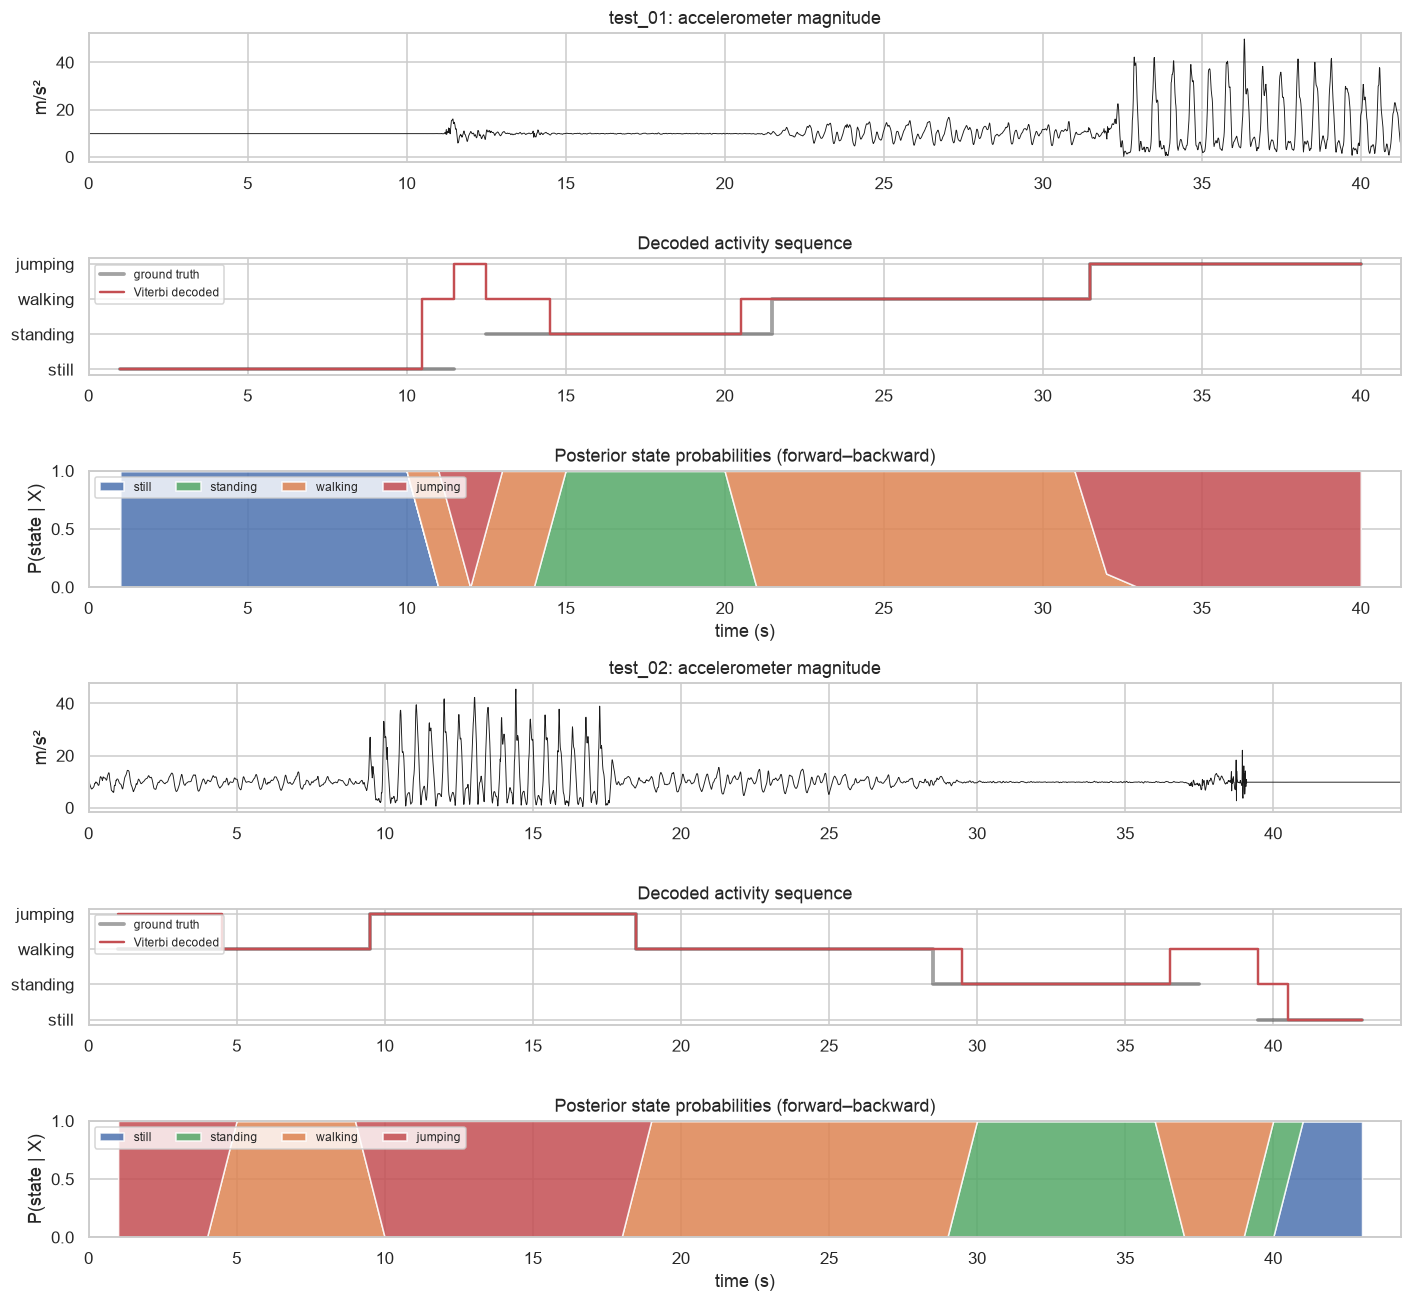

In [19]:
# Decoded sequences: signal, ground truth vs Viterbi path, posterior probabilities
lvl = {s: i for i, s in enumerate(STATES)}
fig, axes = plt.subplots(3 * len(test), 1, figsize=(13, 3.2 * 3 * len(test) / 1.6),
                         gridspec_kw={"height_ratios": [1, 0.9, 0.9] * len(test)}, sharex=False)
for i, (t, fdf) in enumerate(zip(test, test_feats)):
    a0, a1, a2 = axes[3 * i], axes[3 * i + 1], axes[3 * i + 2]
    df = t["df"]
    a0.plot(df.seconds_elapsed, np.linalg.norm(df[["acc_x", "acc_y", "acc_z"]], axis=1), lw=0.6, c="k")
    a0.set(title=f"{t['file']}: accelerometer magnitude", ylabel="m/s²")
    truth = fdf.label.map(lambda s: lvl.get(s, np.nan))
    a1.step(fdf.t_center, truth, where="mid", c="k", lw=2.5, alpha=0.4, label="ground truth")
    a1.step(fdf.t_center, fdf.pred.map(lvl), where="mid", c="#C44E52", lw=1.6, label="Viterbi decoded")
    a1.set(yticks=range(K), yticklabels=STATES, title="Decoded activity sequence")
    a1.legend(loc="upper left", fontsize=8)
    a2.stackplot(fdf.t_center, fdf[[f"p_{s}" for s in STATES]].T.values, colors=[COLORS[s] for s in STATES],
                 labels=STATES, alpha=0.85)
    a2.set(ylabel="P(state | X)", title="Posterior state probabilities (forward–backward)", ylim=(0, 1))
    a2.legend(loc="upper left", ncol=4, fontsize=8)
    for a in (a0, a1, a2):
        a.set_xlim(0, df.seconds_elapsed.iloc[-1])
    a2.set_xlabel("time (s)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig8_decoded_sequences.png"); plt.show()

### 5.1 Fully unsupervised Baum–Welch (robustness check)
Because the labelled initialisation is already at (or next to) the likelihood optimum, the model above converges in very few iterations.
To show that Baum–Welch genuinely *discovers* the activity structure, we also train from an **uninformed** start
(means/variances from unlabelled k-means clusters, uniform π, generic sticky A; no labels) and only afterwards map each learned
hidden state to the activity that most of its training windows belong to.

converged=True after 3 iterations; state -> activity mapping: {0: 'walking', 1: 'standing', 2: 'jumping', 3: 'still'}
training agreement with true labels: 1.000
unsupervised-HMM test accuracy (after mapping): 0.863


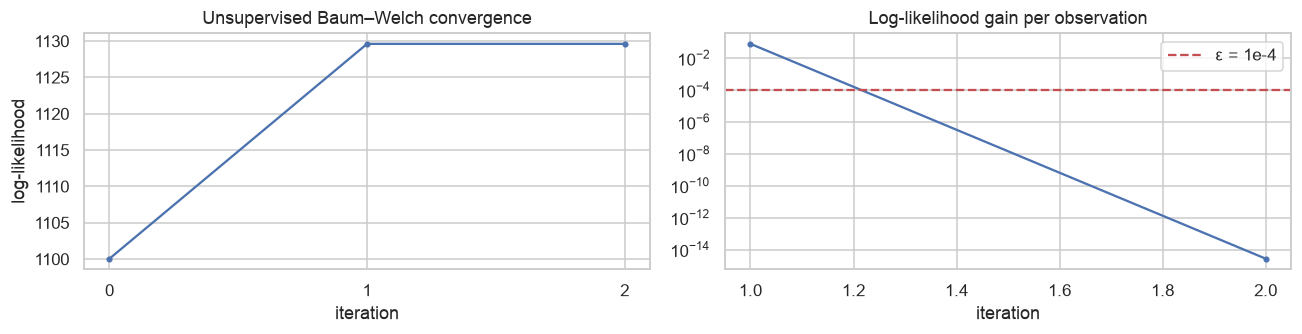

In [20]:
Xall, yall = np.vstack(train_X), np.concatenate(train_y)


def kmeans_init(X, K, seed, n_iter=50):
    # k-means++ seeding followed by Lloyd iterations; labels are NOT used.
    r = np.random.default_rng(seed)
    C = [X[r.integers(len(X))]]
    for _ in range(K - 1):
        d = np.min([((X - c) ** 2).sum(axis=1) for c in C], axis=0)
        C.append(X[r.choice(len(X), p=d / d.sum())])
    C = np.array(C)
    for _ in range(n_iter):
        lab = ((X[:, None] - C[None]) ** 2).sum(axis=2).argmin(axis=1)
        C = np.array([X[lab == k].mean(axis=0) if np.any(lab == k) else C[k] for k in range(K)])
    return C, lab


C, lab = kmeans_init(Xall, K, seed=0)
unsup = GaussianHMM(K)
unsup.means = C.copy()
unsup.vars = np.array([np.maximum(Xall[lab == k].var(axis=0), unsup.var_floor) for k in range(K)])
unsup.pi = np.full(K, 1 / K); unsup.A = np.full((K, K), 0.1 / (K - 1)); np.fill_diagonal(unsup.A, 0.9)
unsup.fit(train_X, tol=1e-4, max_iter=500, verbose=False)

z_tr = np.concatenate([unsup.viterbi(X)[0] for X in train_X])
mapping = {k: STATES[np.bincount(yall[z_tr == k], minlength=K).argmax()] for k in range(K)}
print(f"converged={unsup.converged} after {len(unsup.history)} iterations; state -> activity mapping: {mapping}")
print(f"training agreement with true labels: {np.mean(np.array([mapping[k] for k in z_tr]) == np.array(STATES)[yall]):.3f}")
y_unsup = np.concatenate([[mapping[k] for k in unsup.viterbi(zscore(f))[0]] for f in test_feats])
m_te = test_all.label.isin(STATES).values
print(f"unsupervised-HMM test accuracy (after mapping): {np.mean(y_unsup[m_te] == test_all.label.values[m_te]):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(unsup.history, marker="o", ms=3); ax[0].set(title="Unsupervised Baum–Welch convergence",
                                                       xlabel="iteration", ylabel="log-likelihood")
ax[0].xaxis.get_major_locator().set_params(integer=True)
ax[1].plot(range(1, len(unsup.history)), np.maximum(np.diff(unsup.history), 1e-12) / sum(map(len, train_X)), marker="o", ms=3); ax[1].axhline(1e-4, c="r", ls="--", label="ε = 1e-4")
ax[1].set(yscale="log", title="Log-likelihood gain per observation", xlabel="iteration"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig9_unsupervised_bw.png"); plt.show()

### 6.1 Ablation: effect of Baum–Welch and of temporal decoding
To understand *why* the HMM helps, we compare (a) the labelled-initialisation model **before** Baum–Welch, and (b) a
memory-less classifier that labels each window independently by its most likely emission (no transition model).

In [21]:
pre = GaussianHMM(K).init_from_labels(train_X, train_y)
for k, v in init_snapshot.items():
    setattr(pre, k, v.copy())
X_scored = [(zscore(f), f.label.isin(STATES).values, f.label.values) for f in test_feats]

def acc_of(pred_fn):
    c = n = 0
    for X, m, y in X_scored:
        p = np.array(STATES)[pred_fn(X)]
        c += np.sum(p[m] == y[m]); n += m.sum()
    return c / n

ablation = pd.DataFrame({
    "model": ["Emission-only (no transitions)", "HMM before Baum–Welch (labelled init)", "HMM after Baum–Welch (final)"],
    "test accuracy": [acc_of(lambda X: hmm.log_emissions(X).argmax(1)), acc_of(lambda X: pre.viterbi(X)[0]),
                      acc_of(lambda X: hmm.viterbi(X)[0])]})
train_acc = np.mean(np.concatenate([hmm.viterbi(X)[0] == y for X, y in zip(train_X, train_y)]))
print(f"training-set Viterbi accuracy: {train_acc:.3f}")
ablation.round(3)

training-set Viterbi accuracy: 1.000


,model,test accuracy
0,Emission-only (no transitions),0.862
1,HMM before Baum–Welch (labelled init),0.862
2,HMM after Baum–Welch (final),0.862


## 7. Summary
The final metrics table, figures (saved in `figures/`) and discussion are reported in `report/HMM_Activity_Report.pdf`. Key observations
are discussed there: which activities were easiest/hardest to separate, how the learned transition matrix reflects
realistic behaviour, the effect of sensor noise and sampling rate, and possible improvements.